## Step 1: Dataset Loading and Initial Inspection

In [11]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [12]:
%pip install seaborn
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.


In [13]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [14]:
# Load Dataset
df = pd.read_csv('credit_card_fraud_drift_2026.csv')

In [15]:
# Dataset Shape
df.shape

(120000, 73)

In [16]:
# First Five Rows
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [17]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 73 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   transaction_id                      120000 non-null  object 
 1   customer_id                         120000 non-null  object 
 2   card_id                             120000 non-null  object 
 3   merchant_id                         120000 non-null  object 
 4   transaction_datetime                120000 non-null  object 
 5   month                               120000 non-null  int64  
 6   week_of_year                        120000 non-null  int64  
 7   drift_phase                         120000 non-null  int64  
 8   days_into_phase                     120000 non-null  int64  
 9   drift_magnitude                     120000 non-null  float64
 10  transaction_amount                  120000 non-null  float64
 11  merchant_category         

In [18]:
# Target Distribution
df['is_fraud'].value_counts()

is_fraud
0    108613
1     11387
Name: count, dtype: int64

In [19]:
# Target Percentage
df['is_fraud'].value_counts(normalize=True) * 100

is_fraud
0    90.510833
1     9.489167
Name: proportion, dtype: float64

In [20]:
# Create 10,000 Row Sample
from sklearn.model_selection import train_test_split

df, _ = train_test_split(
    df,
    train_size=10000,
    stratify=df['is_fraud'],
    random_state=42
)

df = df.reset_index(drop=True)

df.shape

(10000, 73)

In [21]:
# Sample Target Distribution
df['is_fraud'].value_counts()

is_fraud
0    9051
1     949
Name: count, dtype: int64

In [22]:
# Sample Target Percentage
df['is_fraud'].value_counts(normalize=True) * 100

is_fraud
0    90.51
1     9.49
Name: proportion, dtype: float64

## Step 2 – Exploratory Data Analysis (EDA)

In [23]:
# Missing Values
df.isnull().sum()[df.isnull().sum() > 0]

dispute_delay_days        9771
dispute_event_datetime    9771
adjudication_datetime     9771
dtype: int64

In [24]:
# Check Duplicate Rows
df.duplicated().sum()

0

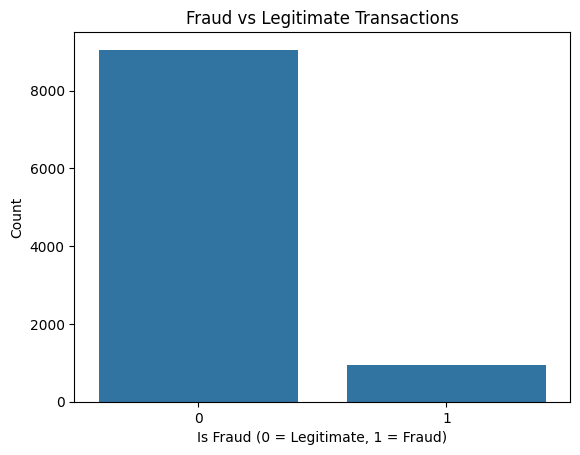

In [25]:
# Fraud Distribution
sns.countplot(data=df, x='is_fraud')
plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('Is Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Count')
plt.show()

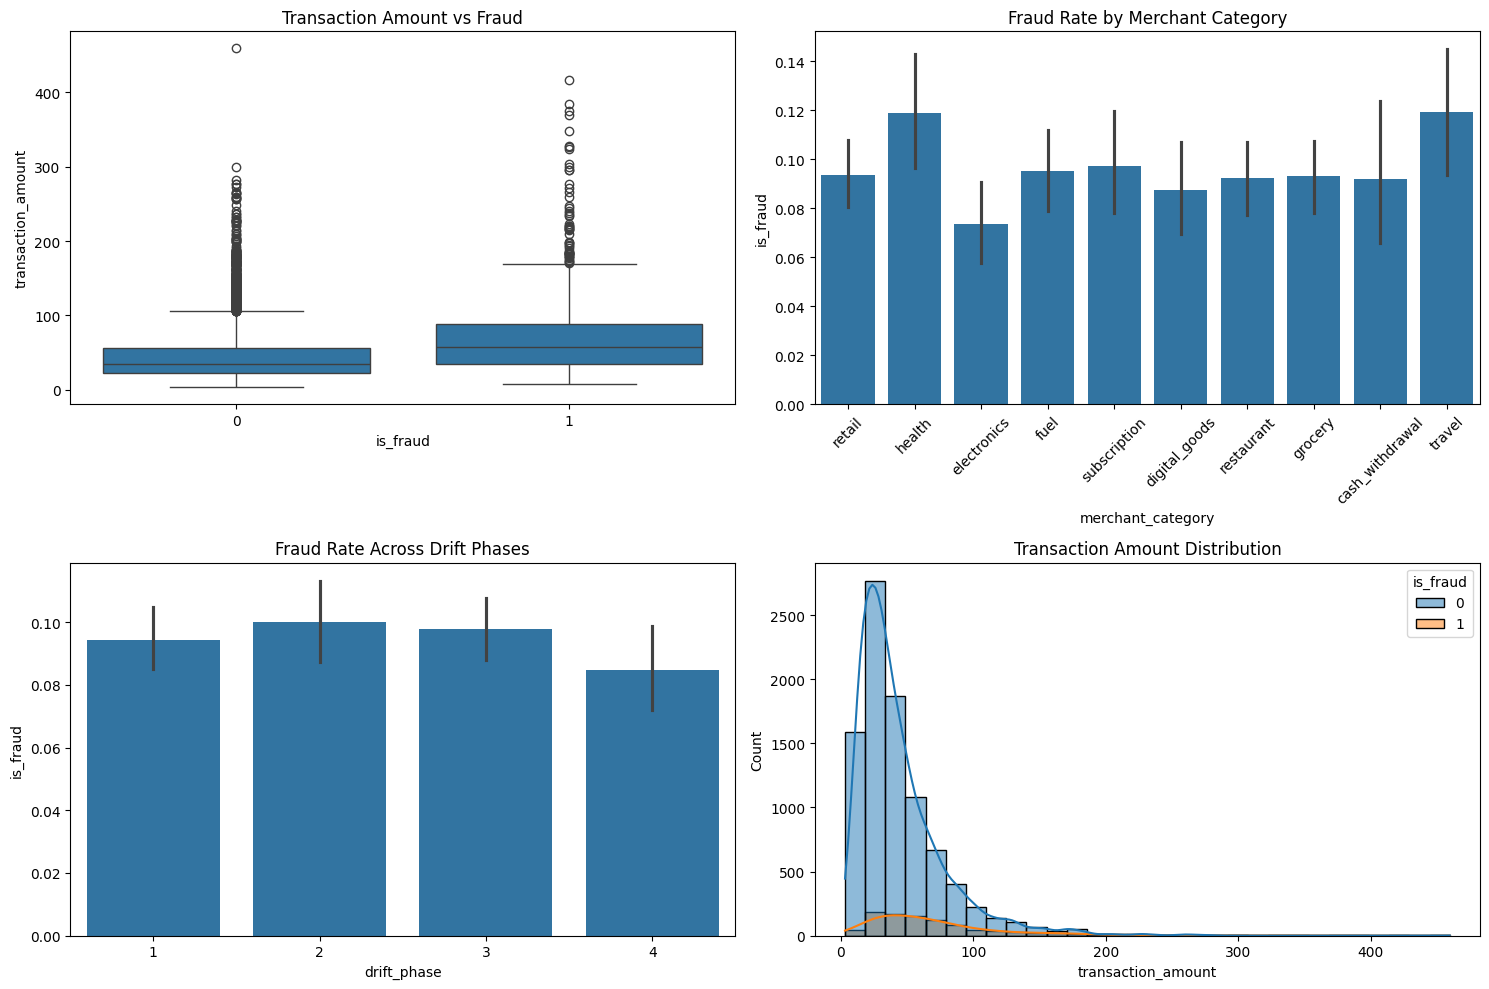

In [26]:
# EDA - Important Visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Transaction Amount vs Fraud
sns.boxplot(data=df, x='is_fraud', y='transaction_amount', ax=axes[0, 0])
axes[0, 0].set_title('Transaction Amount vs Fraud')

# 2. Fraud by Merchant Category
sns.barplot(data=df, x='merchant_category', y='is_fraud', ax=axes[0, 1])
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].set_title('Fraud Rate by Merchant Category')

# 3. Fraud Across Drift Phases
sns.barplot(data=df, x='drift_phase', y='is_fraud', ax=axes[1, 0])
axes[1, 0].set_title('Fraud Rate Across Drift Phases')

# 4. Transaction Amount Distribution
sns.histplot(data=df, x='transaction_amount', hue='is_fraud',
             bins=30, kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Transaction Amount Distribution')

plt.tight_layout()
plt.show()

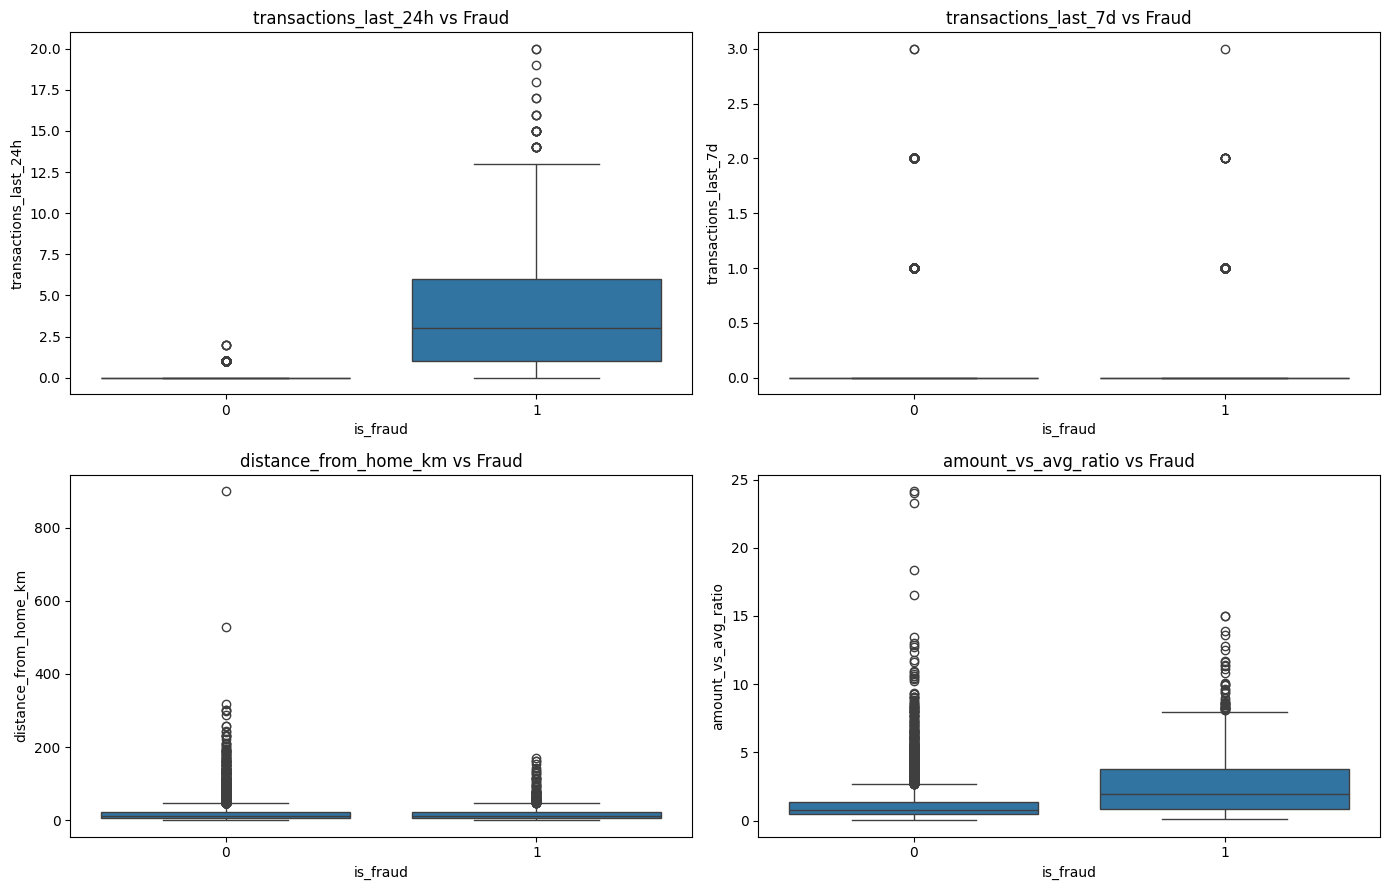

In [27]:
# Numerical Features vs Fraud
features = [
    'transactions_last_24h',
    'transactions_last_7d',
    'distance_from_home_km',
    'amount_vs_avg_ratio'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=df, x='is_fraud', y=feature, ax=ax)
    ax.set_title(f'{feature} vs Fraud')

plt.tight_layout()
plt.show()

## Step 3 – Data Preprocessing

In [28]:
# Remove Target Leakage Columns
drop_cols = [
    'fraud_type',
    'fraud_amount_lost',
    'dispute_filed',
    'post_transaction_outcome',
    'dispute_adjudicated_friendly_fraud',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime',
    'dispute_regime',
    'prior_dispute_ratio_90d'
]

df = df.drop(columns=drop_cols)

In [29]:
# Check Remaining Missing Values
df.isnull().sum().sum()

0

In [30]:
# Identify Categorical Columns
df.select_dtypes(include='object').columns.tolist()

['transaction_id',
 'customer_id',
 'card_id',
 'merchant_id',
 'transaction_datetime',
 'merchant_category',
 'merchant_country',
 'transaction_day_of_week',
 'customer_gender',
 'customer_country',
 'transaction_channel',
 'device_type',
 'browser',
 'email_domain',
 'drift_phase_name',
 'transaction_time_target']

In [31]:
# Remove Identifier Columns
df = df.drop(columns=[
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id'
])

In [32]:
# Convert Transaction Date
df['transaction_datetime'] = pd.to_datetime(df['transaction_datetime'])

In [33]:
# Remove Alternative Target
df = df.drop(columns=['transaction_time_target'])

In [34]:
# Identify Feature Types
categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: ['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_country', 'transaction_channel', 'device_type', 'browser', 'email_domain', 'drift_phase_name']
Numerical Columns: ['month', 'week_of_year', 'drift_phase', 'days_into_phase', 'drift_magnitude', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h'

In [35]:
# Sort Data by Transaction Time
df = df.sort_values('transaction_datetime').reset_index(drop=True)

In [36]:
# Check Transaction Date Range
print("Start Date:", df['transaction_datetime'].min())
print("End Date:", df['transaction_datetime'].max())

Start Date: 2026-01-01 01:21:00
End Date: 2026-06-30 23:36:00


## Step 4 – Train-Test Spli

In [37]:
# Chronological Train-Test Split
split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training Data:", train_df.shape)
print("Testing Data:", test_df.shape)
print("Training Period:", train_df['transaction_datetime'].min(), "to", train_df['transaction_datetime'].max())
print("Testing Period:", test_df['transaction_datetime'].min(), "to", test_df['transaction_datetime'].max())

Training Data: (8000, 58)
Testing Data: (2000, 58)
Training Period: 2026-01-01 01:21:00 to 2026-05-25 14:11:00
Testing Period: 2026-05-25 14:17:00 to 2026-06-30 23:36:00


In [38]:
# Fraud Distribution in Train and Test
print("Training Set:")
print(train_df['is_fraud'].value_counts(normalize=True) * 100)

print("\nTesting Set:")
print(test_df['is_fraud'].value_counts(normalize=True) * 100)

Training Set:
is_fraud
0    90.3875
1     9.6125
Name: proportion, dtype: float64

Testing Set:
is_fraud
0    91.0
1     9.0
Name: proportion, dtype: float64


In [39]:
# Prepare Model Features
exclude_cols = [
    'is_fraud',
    'transaction_datetime',
    'drift_phase_name',
    'label_available',
    'label_delay_days',
    'pseudo_label',
    'transaction_time_eligible'
]

X_train = train_df.drop(columns=exclude_cols)
y_train = train_df['is_fraud']

X_test = test_df.drop(columns=exclude_cols)
y_test = test_df['is_fraud']

In [40]:
# Remove Drift Metadata from Model Features
drift_cols = [
    'drift_phase',
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag',
    'synthetic_id_camouflage_score'
]

X_train = X_train.drop(columns=drift_cols)
X_test = X_test.drop(columns=drift_cols)

## Step 5 – Feature Scaling

In [41]:
# Feature Scaling and Encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_cols = X_train.select_dtypes(include='object').columns.tolist()
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (8000, 104)
Testing Shape: (2000, 104)


In [42]:
# Import Pipeline Libraries
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [43]:
# Create Preprocessing Pipeline

categorical_cols = X_train.select_dtypes(include='object').columns.tolist()
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

## Step 6 – Model Building

In [44]:
# Build Logistic Regression Model
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])



In [45]:
lr_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [46]:
y_pred_lr = lr_model.predict(X_test)

In [47]:
# Evaluate Logistic Regression Model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

Accuracy: 0.993
Precision: 0.9560439560439561
Recall: 0.9666666666666667
F1 Score: 0.9613259668508287


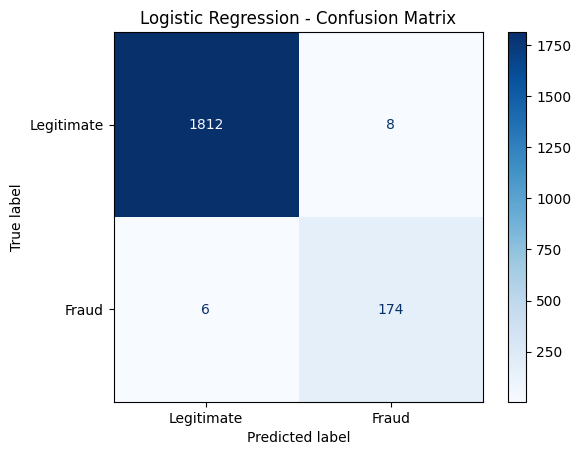

In [48]:
# Logistic Regression Confusion Matrix
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraud']
).plot(cmap='Blues')

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [49]:
# Random Forest Model - Build, Train & Predict
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])



In [50]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [51]:
y_pred_rf = rf_model.predict(X_test)

In [52]:
# Evaluate Random Forest Model
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.998
Precision: 1.0
Recall: 0.9777777777777777
F1 Score: 0.9887640449438202


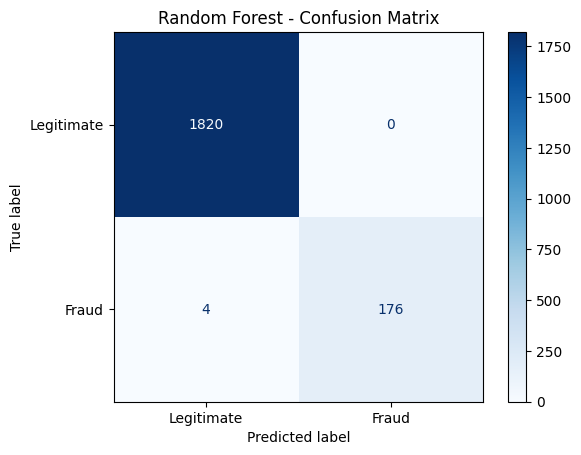

In [53]:
# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Legitimate', 'Fraud']
).plot(cmap='Blues')

plt.title('Random Forest - Confusion Matrix')
plt.show()

In [54]:
# Gradient Boosting - Build, Train & Predict
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

gb_model

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
# Evaluate Gradient Boosting Model
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

Accuracy: 0.9955
Precision: 0.9672131147540983
Recall: 0.9833333333333333
F1 Score: 0.9752066115702479


## Step 7 – Cross-Validation and Hyperparameter Tuning

In [56]:
# Import Cross-Validation Libraries
from sklearn.model_selection import TimeSeriesSplit, cross_validate

In [57]:
# Logistic Regression Cross-Validation
cv = TimeSeriesSplit(n_splits=5)

cv_results_lr = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

print("Accuracy:", cv_results_lr['test_accuracy'].mean())
print("Precision:", cv_results_lr['test_precision'].mean())
print("Recall:", cv_results_lr['test_recall'].mean())
print("F1 Score:", cv_results_lr['test_f1'].mean())


Accuracy: 0.9902475618904726
Precision: 0.9463277149904382
Recall: 0.9556709013121083
F1 Score: 0.9506445960877464


In [58]:
# Random Forest Cross-Validation
cv_results_rf = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

print("Accuracy:", cv_results_rf['test_accuracy'].mean())
print("Precision:", cv_results_rf['test_precision'].mean())
print("Recall:", cv_results_rf['test_recall'].mean())
print("F1 Score:", cv_results_rf['test_f1'].mean())

Accuracy: 0.9966991747936984
Precision: 0.9926028985507246
Recall: 0.9738180370087453
F1 Score: 0.9830685701245377


In [59]:
# Gradient Boosting Cross-Validation
cv_results_gb = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

print("Accuracy:", cv_results_gb['test_accuracy'].mean())
print("Precision:", cv_results_gb['test_precision'].mean())
print("Recall:", cv_results_gb['test_recall'].mean())
print("F1 Score:", cv_results_gb['test_f1'].mean())

Accuracy: 0.9971492873218304
Precision: 0.9893939393939395
Recall: 0.9815506812809243
F1 Score: 0.9853585259461083


In [60]:
# Import Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

In [61]:
# Logistic Regression Hyperparameter Tuning
param_grid = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__solver': ['liblinear'],
    'model__class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    lr_model,
    param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__class_weight': None, 'model__solver': 'liblinear'}
Best CV F1 Score: 0.9655325667198577


In [62]:
# Create Best Logistic Regression Model
best_lr_model = grid_search.best_estimator_

best_lr_model

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [63]:
# Tuned Logistic Regression - Prediction & Evaluation
y_pred_tuned = best_lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

Accuracy: 0.994
Precision: 0.9883720930232558
Recall: 0.9444444444444444
F1 Score: 0.9659090909090909


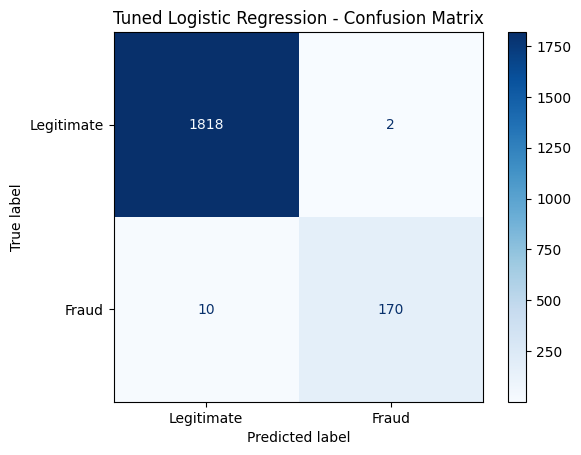

In [64]:
# Tuned Logistic Regression Confusion Matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=['Legitimate', 'Fraud']
).plot(cmap='Blues')

plt.title('Tuned Logistic Regression - Confusion Matrix')
plt.show()

## Step 8 – Concept Drift Analysis

In [65]:
# Fraud Rate by Drift Phase
drift_analysis = df.groupby('drift_phase_name')['is_fraud'].agg(
    Fraud_Count='sum',
    Total_Transactions='count'
)

drift_analysis['Fraud_Rate'] = (
    drift_analysis['Fraud_Count'] / drift_analysis['Total_Transactions'] * 100
)

drift_analysis

,Fraud_Count,Total_Transactions,Fraud_Rate
drift_phase_name,,,
partial_stabilization,139,1642,8.465286
peak_drift,326,3330,9.789790
pre_drift_validation,172,1721,9.994189
stable_training,312,3307,9.434533


In [66]:
# Monthly Fraud Rate
monthly_fraud = df.groupby('month')['is_fraud'].agg(
    Fraud_Count='sum',
    Total_Transactions='count'
)

monthly_fraud['Fraud_Rate'] = (
    monthly_fraud['Fraud_Count'] /
    monthly_fraud['Total_Transactions'] * 100
)

monthly_fraud

,Fraud_Count,Total_Transactions,Fraud_Rate
month,,,
1,161,1761,9.142533
2,151,1546,9.767141
3,172,1721,9.994189
4,160,1643,9.738284
5,166,1687,9.839953
6,139,1642,8.465286


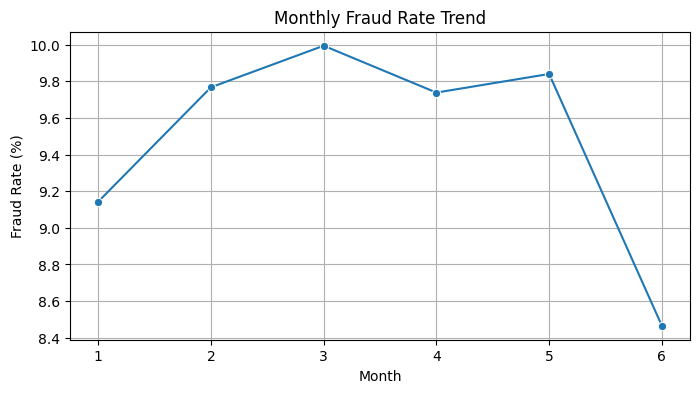

In [67]:
# Monthly Fraud Rate Trend
plt.figure(figsize=(8, 4))

sns.lineplot(
    data=monthly_fraud,
    x=monthly_fraud.index,
    y='Fraud_Rate',
    marker='o'
)

plt.title('Monthly Fraud Rate Trend')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(monthly_fraud.index)
plt.grid(True)
plt.show()

In [68]:
# Fraud Rate by Drift Phase

phase_fraud = df.groupby('drift_phase_name')['is_fraud'].agg(
    Fraud_Count='sum',
    Total_Transactions='count'
)

phase_fraud['Fraud_Rate'] = (
    phase_fraud['Fraud_Count'] /
    phase_fraud['Total_Transactions'] * 100
)

phase_fraud

,Fraud_Count,Total_Transactions,Fraud_Rate
drift_phase_name,,,
partial_stabilization,139,1642,8.465286
peak_drift,326,3330,9.789790
pre_drift_validation,172,1721,9.994189
stable_training,312,3307,9.434533


In [69]:
# Average Transaction Amount by Drift Phase

df.groupby('drift_phase_name')['transaction_amount'].mean().round(2)

drift_phase_name
partial_stabilization    46.27
peak_drift               46.67
pre_drift_validation     46.15
stable_training          47.75
Name: transaction_amount, dtype: float64

In [70]:
# Transaction Frequency by Drift Phase

df.groupby('drift_phase_name')['transactions_last_24h'].mean().round(2)

drift_phase_name
partial_stabilization    0.42
peak_drift               0.46
pre_drift_validation     0.41
stable_training          0.39
Name: transactions_last_24h, dtype: float64

In [71]:
# Model Performance by Drift Phase

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

drift_test = test_df.copy()
drift_test['Actual'] = y_test
drift_test['Predicted'] = y_pred_tuned

drift_test.groupby('drift_phase_name').apply(
    lambda group: pd.Series({
        'Accuracy': accuracy_score(group['Actual'], group['Predicted']),
        'Precision': precision_score(group['Actual'], group['Predicted'], zero_division=0),
        'Recall': recall_score(group['Actual'], group['Predicted'], zero_division=0),
        'F1_Score': f1_score(group['Actual'], group['Predicted'], zero_division=0)
    }),
    include_groups=False
).round(3)

,Accuracy,Precision,Recall,F1_Score
drift_phase_name,,,,
partial_stabilization,0.995,1.000,0.935,0.967
peak_drift,0.992,0.952,0.976,0.964


In [72]:
# Test Data Distribution by Drift Phase

test_df['drift_phase_name'].value_counts()

drift_phase_name
partial_stabilization    1642
peak_drift                358
Name: count, dtype: int64

## Step 9 – Final Model Saving and Documentation

In [73]:
# Save Final Logistic Regression Model

import joblib

joblib.dump(best_lr_model, 'credit_card_fraud_model.pkl')

['credit_card_fraud_model.pkl']

In [74]:
# Verify Saved Model

import os

os.path.exists('credit_card_fraud_model.pkl')

True

In [75]:
print(X_train.columns.tolist())

['month', 'week_of_year', 'days_into_phase', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'pos_entry_fallback', 'pin_retry_count_24h']


In [2]:
import sklearn

print(sklearn.__version__)

1.7.2
